<a href="https://colab.research.google.com/github/febriyanasn/ML-Flight-Prediction/blob/main/flight_price_classification_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deteksi Penawaran Harga dan Segmentasi Pemesanan Tiket Pesawat

**A. Background | B. Business Problem | C. Data and Data Source | D. Kasus 1: Classification | E. Kasus 2: Clustering | F. Findings | G. Solusi dan Rekomendasi**

Notebook ini melanjutkan analisis di `flight_price_analysis_and_modelling_prediction.ipynb`. Pada notebook sebelumnya mengukur faktor yang mendorong tarif tiket dan membangun model regresi Random Forest dengan R² 0,985. Model tersebut menghasilkan angka prediksi, sedangkan ada dua kebutuhan bisnis tambahan yang masih belum terjawab, yaitu:

1. **Kasus 1, Klasifikasi.** Penumpang yang melihat tarif tidak tahu apakah tarif itu murah, wajar, atau mahal untuk penerbangannya. Model klasifikasi akan memberi label pada setiap tarif: Deal, Fair, atau Overpriced.
2. **Kasus 2, Clustering.** Tim pemasaran mengasumsikan ada segmen penumpang, misalnya pebisnis premium dan penumpang hemat, tetapi belum ada bukti dari data. Clustering menguji apakah segmen itu memang ada dan berapa jumlah segmen yang layak ditindaklanjuti.

## A. Background

Sebelum menyusun faktor pendorong harga: kelas kabin (9,2 kali), jendela pemesanan (2,7 kali), maskapai (sekitar 2 kali), waktu penerbangan (1,8 kali), jumlah transit (1,77 kali), rute (1,7 kali), dan durasi (lemah). Model Random Forest memprediksi tarif dengan MAPE 6,4%.

Angka prediksi tersebut belum menjawab dua kebutuhan:

1. **Menilai satu tarif.** Prediksi 12.400 INR tidak memberi tahu penumpang apakah tarif 11.900 INR tergolong murah atau mahal.
2. **Mengelompokkan pemesanan.** Satu strategi untuk 300 ribu pemesanan hanya cukup kalau tidak ada kelompok dengan karakter berbeda.

Kedua kebutuhan ini, dengan data yang sama dapat dilakukan proyeksi dengan classification dan clustering.

## B. Business Problem

### B.1 Kasus 1 - Klasifikasi : Mendeteksi Penawaran Tarif Terbaik.

Penumpang menilai tarif dengan intuisi, tanpa melihat acuan pasar secara data. Sementara itu platform pemesanan membutuhkan kriteria yang konsisten untuk menampilkan lencana/badge *good deal*.

Masalah bisnis: **tentukan apakah tarif satu pemesanan tergolong Deal, Fair, atau Overpriced dibandingkan harga pasar untuk rute, kelas kabin, dan jendela pemesanan yang sama.**

**How?**

Label berasal dari median harga per kelompok konteks, sehingga seluruh 300.153 baris bisa diberi label. Model dinilai berhasil kalau metrik macro F1 di data uji melampaui baseline kelas mayoritas dan recall seimbang di ketiga kelas.

F1 menggabungkan dua hal jadi satu angka:
- Precision : Dari semua tarif yang model bilang "Deal", berapa yang benar benar Deal?
- Recall : Dari semua tarif yang sebenarnya Deal, berapa yang berhasil ditemukan model?

### B.2 Kasus 2 - Clustering:  Segmentasi Pemesanan

Tim pemasaran membagi penumpang berdasarkan asumsi, misalnya pebisnis yang memesan mepet versus penumpang hemat yang memesan jauh hari. Kalau asumsi itu keliru, diskon jatuh ke segmen yang tidak sensitif terhadap harga.

Masalah bisnis: **apakah 300.153 pemesanan membentuk kelompok alami, dan berapa kelompok yang layak ditindaklanjuti?**

**How?**

Pendekatannya K Means pada fitur harga, durasi, jendela pemesanan, jumlah transit, waktu terbang, dan kelas kabin. Hasil dinilai dari silhouette score, stabilitas antar sampel (Adjusted Rand Index), dan kejelasan profil tiap segmen.

## C. Data and Data Source

Dataset sama dengan notebook sebelumnya: `data/flight_dataset.csv`, berisi 300.153 pemesanan penerbangan domestik India dengan 11 kolom, tanpa missing value dan tanpa duplikat. Skema, sumber Kaggle, dan keterbatasannya (tanpa tanggal kalender, waktu hanya dalam bin, satu pasar domestik) sudah dijelaskan di notebook sebelumnya.

Ada dua perbedaan dari model regresi:

1. **Kasus 1 memakai `price` sebagai fitur.** Model regresi memprediksi harga. Model klasifikasi menerima tarif yang dikutip sebagai masukan dan menilainya terhadap struktur pasar.
2. **Kasus 2 tidak memakai label.** Clustering memakai tujuh fitur numerik hasil encoding dan scaling, tanpa variabel target. Profil segmen dibaca dari kolom asli setelah klaster terbentuk.

## D. Kasus 1 - Klasifikasi : Mendeteksi Penawaran Tarif Terbaik.

Alur Kasus 1: konstruksi label dari median pasar, pre-processing, perbandingan lima model, evaluasi model final, dan analisis galat.

### D.1 Import dan Load Data

Import library python yang dibutuhkan.

In [14]:
#--- import library --------------------------------------
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, adjusted_rand_score,
                             silhouette_score)
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance

Load data dari csv, memunculkan dataframe (df) info, kemudian cek missing values dan duplikasi data.

In [15]:
#--- load dataset --------------------------------------
plt.rcParams['figure.figsize'] = (11, 4)
pd.set_option('display.width', 140)

df = pd.read_csv('data/flight_dataset.csv', index_col=0)
print(f'Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')
print(f'Missing: {df.isna().sum().sum()} | Duplicates: {df.duplicated().sum()}')
df.head()

Rows: 300,153 | Columns: 11
Missing: 0 | Duplicates: 0


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


### D.2 Pembuatan / Konstruksi Label: Deal, Fair, Overpriced

Label ditentukan dari rasio harga tiket terhadap kelompok median harga pasar konteksnya: kombinasi rute, kelas kabin, dan jendela pemesanan. Jendela pemesanan ikut menjadi acuan karena `days_left` adalah faktor harga terkuat kedua (2,7 kali). Tiket yang dibeli dalam waktu mepet memang wajar mahal, dan melabelinya dengan 'Overpriced' akan menyesatkan.

Tahapan konstruksi desain label:

1. **Median dihitung dari data latih**, memisahkannya dari data uji/testing.
2. **Ambang ±15%.** Rasio di bawah 0,85 berarti Deal, di atas 1,15 berarti Overpriced, sisanya Fair.
3. **Fallback bertingkat.** Kelompok dengan kurang dari 20 pemesanan memakai median rute dan kelas, lalu median kelas.

Kelompok konteks (rute x kelas x jendela): 300
Ukuran kelompok: median 588 | min 18 | maks 3351
Fallback ke median rute+kelas: 25 baris | ke median kelas: 0 baris

Rasio harga terhadap median pasar:
count    300153.000
mean          1.014
std           0.379
min           0.151
25%           0.804
50%           1.000
75%           1.166
max           7.108

Label balance (%): {'Fair': 44.2, 'Deal': 29.4, 'Overpriced': 26.4}


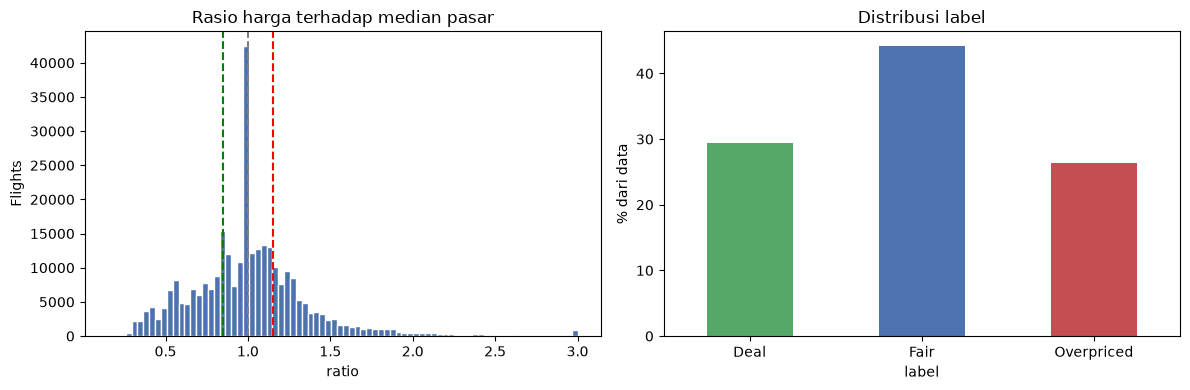

In [16]:
# --- Konteks: rute dan jendela pemesanan ----------------------------------
dfc = df.drop(columns=['flight']).copy()
dfc['route'] = dfc['source_city'] + ' -> ' + dfc['destination_city']
dfc['window'] = pd.cut(dfc['days_left'], bins=[0, 2, 7, 14, 30, 49],
                       labels=['1-2', '3-7', '8-14', '15-30', '31-49']).astype(str)

# --- Split indeks lebih dulu: median acuan hanya dari data training, memisahkan data training dan testing ----------
train_idx, test_idx = train_test_split(np.arange(len(dfc)), test_size=0.2,
                                       random_state=42)
tr = dfc.iloc[train_idx]

#--- Hitung median harga per rute, kelas, dan jendela pemesanan ----------------
med_rkw = tr.groupby(['route', 'class', 'window'])['price'].agg(['median', 'size'])
med_rk = tr.groupby(['route', 'class'])['price'].median()
med_k = tr.groupby('class')['price'].median()

#--- Hitung harga acuan per baris, dengan fallback ke median rute+kelas, lalu ke median kelas ---
key_rkw = pd.MultiIndex.from_arrays([dfc['route'], dfc['class'], dfc['window']])
key_rk = pd.MultiIndex.from_arrays([dfc['route'], dfc['class']])

ref_v = med_rkw['median'].reindex(key_rkw).to_numpy()
size_v = med_rkw['size'].reindex(key_rkw).to_numpy()
ok_v = (size_v >= 20) & ~np.isnan(ref_v)
n_fb1 = int((~ok_v).sum())
ref_v = np.where(ok_v, ref_v, med_rk.reindex(key_rk).to_numpy())
n_fb2 = int(np.isnan(ref_v).sum())
ref_v = np.where(np.isnan(ref_v), med_k.reindex(dfc['class']).to_numpy(), ref_v)

dfc['ref_price'] = ref_v
dfc['ratio'] = dfc['price'] / dfc['ref_price']

DEAL_T, OVER_T = 0.85, 1.15
dfc['label'] = pd.cut(dfc['ratio'], bins=[0, DEAL_T, OVER_T, np.inf],
                      labels=['Deal', 'Fair', 'Overpriced']).astype(str)

sizes = med_rkw['size']

#--- Statistik ringkas dan visualisasi ---------------------------------------
print(f'Kelompok konteks (rute x kelas x jendela): {len(med_rkw)}')
print(f'Ukuran kelompok: median {sizes.median():.0f} | min {sizes.min():.0f} | maks {sizes.max():.0f}')
print(f'Fallback ke median rute+kelas: {n_fb1:,} baris | ke median kelas: {n_fb2:,} baris')
print('\nRasio harga terhadap median pasar:')
print(dfc['ratio'].describe().round(3).to_string())
bal = dfc['label'].value_counts(normalize=True).mul(100).round(1)
print(f'\nLabel balance (%): {bal.to_dict()}')

#--- Visualisasi distribusi rasio harga dan label -----------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(dfc['ratio'].clip(upper=3), bins=80, color='#4C72B0', edgecolor='white')
for t, c in [(DEAL_T, 'green'), (1.0, 'gray'), (OVER_T, 'red')]:
    ax[0].axvline(t, color=c, ls='--', lw=1.5)
ax[0].set(title='Rasio harga terhadap median pasar', xlabel='ratio', ylabel='Flights')
bal.reindex(['Deal', 'Fair', 'Overpriced']).plot(kind='bar', ax=ax[1],
                                                 color=['#55A868', '#4C72B0', '#C44E52'])
ax[1].set(title='Distribusi label', ylabel='% dari data')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Insight:** 
- Label berhasil dibuat untuk seluruh 300.153 baris. 
- Ada 300 kelompok konteks (rute × kelas × jendela) dengan median 588 pemesanan per kelompok. 
- Hanya 25 baris (0,008%) yang memakai fallback median rute dan kelas karena kelompoknya berisi kurang dari 20 pemesanan. 

Rasio harga terhadap median pasar berkisar dari 0,151 sampai 7,108, dengan median 1,000. Ambang ±15% menghasilkan sebaran kelas yang cukup seimbang: Fair 44,2%, Deal 29,4%, Overpriced 26,4%. Setiap kelas punya puluhan ribu baris, jadi tahap pemodelan tidak perlu penanganan imbalance.

### D.3 Preprocessing dan Split Data

Fitur model adalah seluruh atribut pemesanan, **termasuk `price`**. Model perlu melihat tarif yang dikutip untuk menilainya terhadap harga lazim per konteks.

Rute dan jendela pemesanan tidak dibuat sebagai fitur terpisah. Keduanya sudah terwakili oleh `source_city`, `destination_city`, dan `days_left`. Model mempelajari struktur itu sendiri, bukan menyalin tabel lookup.

1. Tujuh kolom kategorikal dikodekan one hot di dalam `Pipeline`, dipasang hanya pada data latih.
2. `duration`, `days_left`, dan `price` distandarisasi untuk model linear. Model pohon tidak terpengaruh.
3. Split 80:20 memakai indeks yang sama dengan perhitungan median di D.2. Acuan label dan data latih berasal dari subset yang sama.

In [17]:
#--- klasifikasi label ------------------------------------------------------
cat_cols = ['airline', 'source_city', 'departure_time', 'stops',
            'arrival_time', 'destination_city', 'class']
num_cols = ['duration', 'days_left', 'price']

X = dfc[cat_cols + num_cols]
y = dfc['label']

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

#--- Preprocessing pipeline: one-hot encoding untuk kategori, standardisasi untuk numerik ---
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols),
])

n_feat = preprocess.fit(X_train).transform(X_train).shape[1]
print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,} | Fitur setelah encoding: {n_feat}')

balance = pd.DataFrame({
    'train %': y_train.value_counts(normalize=True).mul(100).round(1),
    'test %': y_test.value_counts(normalize=True).mul(100).round(1),
})
balance

Train: 240,122 | Test: 60,031 | Fitur setelah encoding: 38


,train %,test %
label,,
Fair,44.2,44.2
Deal,29.3,29.4
Overpriced,26.5,26.4


### D.4 Baseline dan Perbandingan Model

Lima model diuji, dari sederhana ke kompleks: Dummy Classifier (baseline kelas mayoritas), Logistic Regression, Decision Tree, Random Forest, dan HistGradientBoosting.

Metrik utama adalah **macro F1**, karena ketiga kelas sama penting bagi bisnis. Akurasi menjadi pembanding. Waktu latih dicatat untuk pertimbangan operasional.

                      Accuracy  F1 macro  F1 weighted  Fit (s)
Model                                                         
Dummy (majority)        0.4421    0.2044       0.2710      0.9
Logistic Regression     0.7384    0.7379       0.7377      4.5
Decision Tree           0.9970    0.9970       0.9970      3.3
Random Forest           0.9869    0.9870       0.9869      6.3
HistGradientBoosting    0.9910    0.9911       0.9910     10.3

Model terbaik (F1 macro): Decision Tree


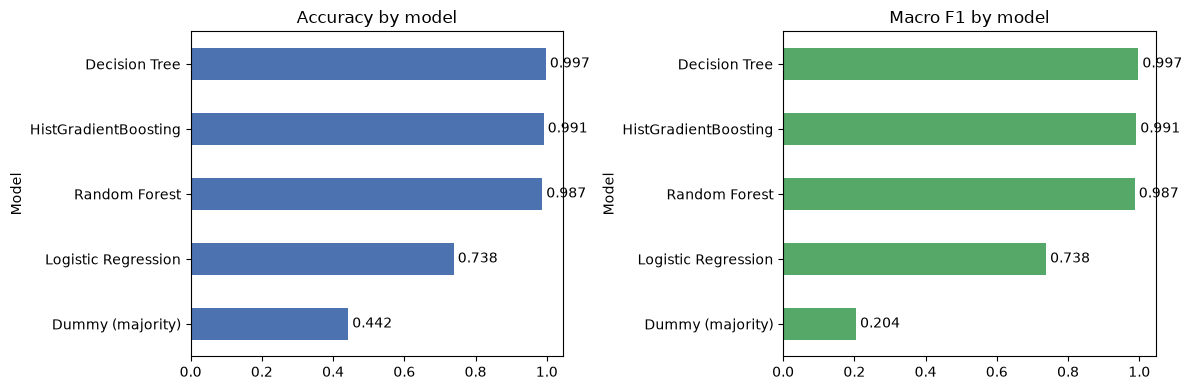

,Accuracy,F1 macro,F1 weighted,Fit (s)
Model,,,,
Dummy (majority),0.4421,0.2044,0.2710,0.9
Logistic Regression,0.7384,0.7379,0.7377,4.5
Decision Tree,0.9970,0.9970,0.9970,3.3
Random Forest,0.9869,0.9870,0.9869,6.3
HistGradientBoosting,0.9910,0.9911,0.9910,10.3


In [18]:
#---Menguji beberapa model klasifikasi  ----------------
models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                            random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
}

#---Metrik evaluasi: akurasi, F1 macro, F1 weighted, dan waktu fitting ----------------
#---Tujuan F1 macro adalah untuk menghitung rata-rata F1 score dari semua kelas tanpa memperhatikan proporsi kelas, sehingga memberikan gambaran kinerja model secara keseluruhan.
#---Tujuan F1 Weighted adalah untuk memberikan bobot pada F1 score setiap kelas sesuai dengan proporsi kelas tersebut dalam dataset, sehingga lebih mencerminkan kinerja model pada dataset yang tidak seimbang.
#--Fit menunjukkan waktu yang dibutuhkan untuk melatih model pada data training, yang penting untuk menilai efisiensi model terutama pada dataset besar.
results, fitted = [], {}
for name, model in models.items():
    t0 = time.time()
    pipe = Pipeline([('pre', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'F1 macro': f1_score(y_test, pred, average='macro'),
        'F1 weighted': f1_score(y_test, pred, average='weighted'),
        'Fit (s)': time.time() - t0,
    })

res_df = pd.DataFrame(results).set_index('Model')
res_df[['Accuracy', 'F1 macro', 'F1 weighted']] = res_df[['Accuracy', 'F1 macro', 'F1 weighted']].round(4)
res_df['Fit (s)'] = res_df['Fit (s)'].round(1)
print(res_df.to_string())

#--Identifikasi model terbaik
best_name = res_df['F1 macro'].idxmax()
print(f'\nModel terbaik (F1 macro): {best_name}')

#--- visualisasi perbandingan metrik evaluasi antar model --------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res_df['Accuracy'].sort_values().plot(kind='barh', ax=ax[0], color='#4C72B0')
ax[0].set_title('Accuracy by model')
res_df['F1 macro'].sort_values().plot(kind='barh', ax=ax[1], color='#55A868')
ax[1].set_title('Macro F1 by model')
for a in ax:
    a.bar_label(a.containers[0], fmt='%.3f', padding=3)
plt.tight_layout(); plt.show()
res_df

**Insight:** Decision Tree terbaik, dengan macro F1 0,9970 dan akurasi 0,9970. Waktu latihnya tercepat kedua (1,7 detik). Random Forest mencapai 0,9870 dan HistGradientBoosting 0,9911. Baseline Dummy hanya 0,2044.

Hasil ini sesuai dengan struktur label. Batas antar kelas berupa ambang harga eksak per kelompok konteks. Satu pohon penuh bisa menirukan ambang itu. Rata rata 100 pohon di Random Forest melunakkan batas yang tajam. Model linear hanya mencapai 0,7379 karena label bergantung pada interaksi konteks yang tidak bisa dipisah secara aditif.

Tiga model pohon berada di atas 0,98, jadi pilihan model tidak mahal secara bisnis. Decision Tree dipilih karena F1 tertinggi dan paling mudah diaudit. Tim non teknis bisa membaca jalur keputusannya aturan demi aturan.

### D.5 Evaluasi Model

Model terbaik dievaluasi dengan empat cara:

1. Confusion matrix, untuk melihat pola error antar kelas.
2. Classification report, untuk presisi dan recall per kelas.
3. Cross validation 5 fold pada data latih, untuk menguji stabilitas.
4. Permutation importance, untuk melihat fitur yang paling menentukan label.

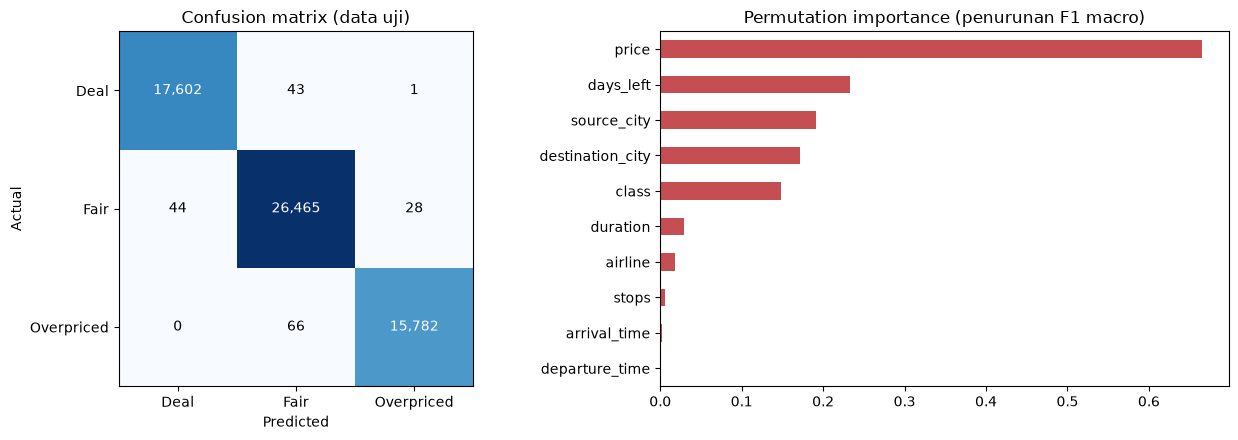

              precision    recall  f1-score   support

        Deal     0.9975    0.9975    0.9975     17646
        Fair     0.9959    0.9973    0.9966     26537
  Overpriced     0.9982    0.9958    0.9970     15848

    accuracy                         0.9970     60031
   macro avg     0.9972    0.9969    0.9970     60031
weighted avg     0.9970    0.9970    0.9970     60031

CV F1 macro (5-fold, data latih): 0.9962 +/- 0.0002

Permutation importance:
price               0.6649
days_left           0.2324
source_city         0.1913
destination_city    0.1711
class               0.1485
duration            0.0294
airline             0.0177
stops               0.0063
arrival_time        0.0021
departure_time      0.0011


In [19]:
final_pipe = fitted[best_name]
pred = final_pipe.predict(X_test)
labels_order = ['Deal', 'Fair', 'Overpriced']

# --- Confusion matrix untuk melihat performa model pada data uji --------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].imshow(cm, cmap='Blues')
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(labels_order)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(labels_order)
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
ax[0].set_title('Confusion matrix (data uji)')
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                   color='white' if cm[i, j] > cm.max() / 2 else 'black')

# --- Permutation importance (10 ribu sampel data uji) ----------------------
rng = np.random.RandomState(42)
idx = rng.choice(len(X_test), 10000, replace=False)
perm = permutation_importance(final_pipe, X_test.iloc[idx], y_test.iloc[idx],
                              n_repeats=5, scoring='f1_macro', random_state=42)
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_s.plot(kind='barh', ax=ax[1], color='#C44E52')
ax[1].set_title('Permutation importance (penurunan F1 macro)')
plt.tight_layout(); plt.show()

#--visualisasi classification report untuk melihat performa model pada data uji --------------------------------------
print(classification_report(y_test, pred, labels=labels_order, digits=4))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_val_score(final_pipe, X_train, y_train, cv=skf, scoring='f1_macro')
print(f'CV F1 macro (5-fold, data latih): {cv.mean():.4f} +/- {cv.std():.4f}')
print('\nPermutation importance:')
print(perm_s.sort_values(ascending=False).round(4).to_string())

**Insight:** Evaluasi final terhadap model dengan confiusion matrix terlihat stabil di semua evaluasi. F1 per kelas mempunyai nilai seragam tinggi: Deal 0,9975, Fair 0,9966, Overpriced 0,9970. Cross validation 5 fold menghasilkan macro F1 0,9962 dengan deviasi ±0,0002, Sehingga angka 0,9970 di data uji bukan kebetulan pembagian data.

Adapun lima fitur teratas menurut permutation importance adalah `price` (0,665), `days_left` (0,232), `source_city` (0,191), `destination_city` (0,171), dan `class` (0,149). Kelima fitur tersebut adalah bahan pembentuk label. Oleh karena itu skor yang tinggi menunjukkan model berhasil menemukan aturan pelabelan. Fitur waktu berangkat dan tiba nyaris tidak dipakai (di bawah 0,003), sejalan dengan temuan EDA bahwa waktu terbang hanya menggeser harga dalam rentang sempit.

### D.6 Analisis Error / Galat

Dua hal yang diperiksa dalam tahap ini:

1. Segmen mana yang paling sering salah diprediksi.
2. Frekuensi dua galat bisnis paling mahal:
- Overpriced yang diprediksi Deal: penumpang disarankan membeli padahal tarifnya mahal. 
- Deal yang diprediksi Overpriced: penumpang kehilangan penawaran bagus.

In [20]:
err = pd.DataFrame({'actual': y_test, 'pred': pred})
err['correct'] = err['actual'] == err['pred']
err['class'] = X_test['class'].to_numpy()
err['window'] = pd.cut(X_test['days_left'], bins=[0, 2, 7, 14, 30, 49],
                       labels=['1-2', '3-7', '8-14', '15-30', '31-49']).astype(str).to_numpy()
err['airline'] = X_test['airline'].to_numpy()

print('Akurasi menurut kelas kabin (%):')
print(err.groupby('class')['correct'].mean().mul(100).round(1).to_string())
print('\nAkurasi menurut jendela pemesanan (%):')
print(err.groupby('window')['correct'].mean().mul(100).round(1).to_string())
print('\nAkurasi menurut maskapai (%):')
print(err.groupby('airline')['correct'].mean().mul(100).round(1).to_string())

cm_df = pd.DataFrame(cm, index=labels_order, columns=labels_order)
opp_as_deal = cm_df.loc['Overpriced', 'Deal']
deal_as_opp = cm_df.loc['Deal', 'Overpriced']
n_opp = cm_df.loc['Overpriced'].sum()
n_deal = cm_df.loc['Deal'].sum()

print('\nGalat bisnis paling mahal:')
print(f'  Overpriced diprediksi Deal : {opp_as_deal:,} dari {n_opp:,} ({opp_as_deal / n_opp * 100:.2f}%)')
print(f'  Deal diprediksi Overpriced : {deal_as_opp:,} dari {n_deal:,} ({deal_as_opp / n_deal * 100:.2f}%)')

Akurasi menurut kelas kabin (%):
class
Business    99.9
Economy     99.6

Akurasi menurut jendela pemesanan (%):
window
1-2      97.3
15-30    99.8
3-7      98.9
31-49    99.9
8-14     99.7

Akurasi menurut maskapai (%):
airline
AirAsia      99.7
Air_India    99.6
GO_FIRST     99.9
Indigo       99.2
SpiceJet     99.7
Vistara      99.9

Galat bisnis paling mahal:
  Overpriced diprediksi Deal : 0 dari 15,848 (0.00%)
  Deal diprediksi Overpriced : 1 dari 17,646 (0.01%)


**Insight:** Error atau galat terkonsentrasi pada pemesanan walam waktu mepet. Akurasi untuk pemesanan 1 sampai 2 hari sebelum berangkat turun ke 97,3%, sedangkan untuk 15 hari atau lebih mencapai 99,9%. Harga di jendela ini paling fluktuatif, jadi label di sana paling mudah meleset. Segmen lain nyaris sempurna: Business 99,9%, Economy 99,6%, dan semua maskapai minimal 99,2% (terendah Indigo).

Dua galat mahal praktis tidak terjadi. 
- Overpriced yang diprediksi Deal: 0 dari 15.848 kasus (0,00%) -> Tidak ada penumpang yang disarankan membeli tarif di atas pasar. 
- Deal yang diprediksi Overpriced: 1 dari 17.646 kasus (0,01%) -> Dengan label ini, galat yang merugikan penumpang hampir tidak ada.

## E. Kasus  2 - Clustering:  Segmentasi Pemesanan

### E.1 Desain Fitur

Segmentasi dilakukan per pemesanan dengan tujuh fitur:

1. `log1p(price)`: harga dikompresi logaritmik karena miring ke kanan.
2. `duration`.
3. `days_left`.
4. Jumlah transit (ordinal 0 sampai 2).
5. Waktu berangkat (ordinal 0 sampai 5, mengikuti urutan jam).
6. Waktu tiba (ordinal 0 sampai 5).
7. Kelas kabin (biner).

Pada tahapan ini kolom maskapai tidak disertakan, supaya segmen terbentuk dari karakter harga dan waktu, bukan dari brand maskalapi. Profil maskapai akan dibaca setelah proses clustering.

Semua fitur distandarisasi agar setiap dimensi menyumbang jarak yang sebanding. K Means dipilih karena cepat pada 300 ribu baris dan menghasilkan segmen berukuran seimbang. Jumlah cluster dipilih dari elbow dan silhouette, lalu diuji ulang dengan stabilitas antar sampel.

In [21]:
#---Clustering untuk menemukan pola harga --------------------------------------
time_map = {'Early_Morning': 0, 'Morning': 1, 'Afternoon': 2,
            'Evening': 3, 'Night': 4, 'Late_Night': 5}
stops_map = {'zero': 0, 'one': 1, 'two_or_more': 2}

#---Membuat fitur untuk clustering --------------------------------------
feat = pd.DataFrame({
    'log_price': np.log1p(df['price']),
    'duration': df['duration'],
    'days_left': df['days_left'],
    'stops': df['stops'].map(stops_map),
    'dep_time': df['departure_time'].map(time_map),
    'arr_time': df['arrival_time'].map(time_map),
    'business': (df['class'] == 'Business').astype(int),
})
print(f'NaN check: {feat.isna().sum().sum()}')

#--- Standarisasi fitur numerik untuk clustering --------------------------------------
#--dilakukan agar fitur numerik memiliki skala yang sama, sehingga tidak ada fitur yang mendominasi dalam proses clustering.
scaler = StandardScaler()
Xc = scaler.fit_transform(feat)
print(f'Matrix clustering: {Xc.shape[0]:,} x {Xc.shape[1]}')
feat.describe().round(2)

NaN check: 0
Matrix clustering: 300,153 x 7


,log_price,duration,days_left,stops,dep_time,arr_time,business
count,300153.00,300153.00,300153.00,300153.00,300153.00,300153.00,300153.00
mean,9.33,12.22,26.00,0.92,1.87,2.70,0.31
std,1.11,7.19,13.56,0.40,1.42,1.35,0.46
min,7.01,0.83,1.00,0.00,0.00,0.00,0.00
25%,8.47,6.83,15.00,1.00,1.00,1.00,0.00
50%,8.91,11.25,26.00,1.00,2.00,3.00,0.00
75%,10.66,16.17,38.00,1.00,3.00,4.00,1.00
max,11.72,49.83,49.00,2.00,5.00,5.00,1.00


### E.2 Pemilihan Jumlah Cluster Optimum

Jumlah cluster k=2 sampai 8 dipindai pada sampel 50 ribu baris, kemudian Silhouette dihitung pada sub-sampel 10 ribu baris, karena kompleksitasnya yang kuadratik.

Pilihan akhir akan mempertimbangkan elbow, silhouette, dan kegunaan bisnis. Segmen yang terlalu banyak sulit ditindaklanjuti kalau profilnya yang mirip.

k=2: inertia=256,661 | silhouette=0.2904 | 0s
k=3: inertia=214,008 | silhouette=0.3079 | 0s
k=4: inertia=177,511 | silhouette=0.3006 | 0s
k=5: inertia=158,202 | silhouette=0.3111 | 0s
k=6: inertia=144,344 | silhouette=0.2637 | 0s
k=7: inertia=132,371 | silhouette=0.2823 | 0s
k=8: inertia=124,403 | silhouette=0.2884 | 1s


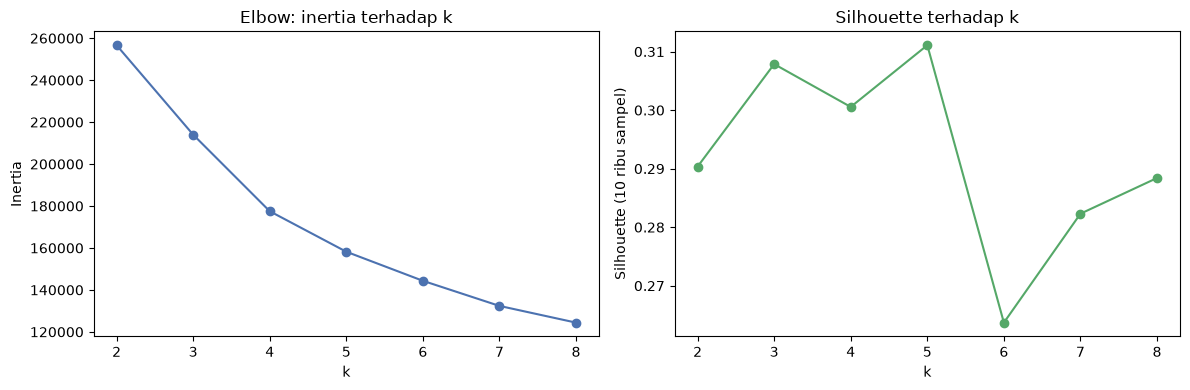

In [22]:
#--- Menentukan jumlah cluster optimal menggunakan metode elbow dan silhouette ----------------------
rng = np.random.RandomState(42)
scan_idx = rng.choice(len(Xc), 50000, replace=False)
Xs = Xc[scan_idx]
sil_idx = rng.choice(len(Xs), 10000, replace=False)

rows = []
for k in range(2, 9):
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    fs = time.time() - t0
    sil = silhouette_score(Xs[sil_idx], km.labels_[sil_idx])
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': sil, 'fit_s': fs})
    print(f'k={k}: inertia={km.inertia_:,.0f} | silhouette={sil:.4f} | {fs:.0f}s')

scan_df = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(scan_df['k'], scan_df['inertia'], marker='o', color='#4C72B0')
ax[0].set(title='Elbow: inertia terhadap k', xlabel='k', ylabel='Inertia')
ax[1].plot(scan_df['k'], scan_df['silhouette'], marker='o', color='#55A868')
ax[1].set(title='Silhouette terhadap k', xlabel='k', ylabel='Silhouette (10 ribu sampel)')
plt.tight_layout(); plt.show()

**Insight:** Silhouette tertinggi ada pada k=5 (0,311), disusul k=3 (0,308) dan k=4 (0,301) dengan nilai selisihnya kecil. Sedangkan Silhouette turun tajam ke 0,264 pada k=6. Kurva inertia melengkung paling jelas antara k=4 dan k=5.

Silhouette sekitar 0,3 berarti cluster saling tumpang tindih. Hal itu dinilai wajar untuk data pemesanan nyata yang mempunyai tingkatan berangsur (gradasi). 
Kesimpulannya k=5 dipilih karena silhouette tertinggi, siku inertia jelas, dan lima segmen masih bisa ditindaklanjuti tim pemasaran.

### E.3 Model Final dan Profil Segmen (Cluster)

Model final dilatih pada seluruh 300.153 baris dengan k=5. Setiap segmen lalu diprofilkan dari data asli: ukuran, median harga, median jendela pemesanan, median durasi, proporsi Business, proporsi penerbangan langsung, sebaran jendela pemesanan, dan maskapai dominan. Nama segmen berasal dari profil itu.

Segmen pada grafis diwakili inisial S.

Kelas kabin per segmen (% baris segmen):
class    Business  Economy
segment                   
0            22.5     77.5
1           100.0      0.0
2             0.0    100.0
3             0.0    100.0
4           100.0      0.0

Jendela pemesanan per segmen (% baris segmen):
days_left  1-2   3-7  8-14  15-30  31-49
segment                                 
0          2.2   8.7  14.5   34.1   40.5
1          2.3  10.2  14.7   33.4   39.3
2          2.6   9.3  14.2   33.8   40.0
3          1.7   7.7  13.9   35.4   41.3
4          1.2   8.8  14.7   34.7   40.6

Maskapai dominan per segmen:
segment
0     Indigo (31%)
1    Vistara (61%)
2    Vistara (41%)
3    Vistara (31%)
4    Vistara (69%)


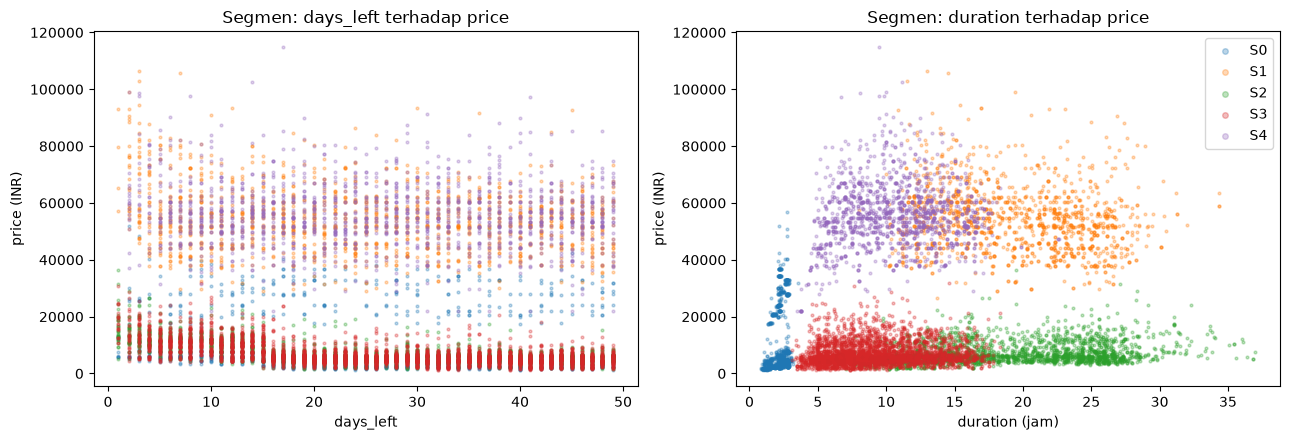

,med_price,med_days,med_dur,pct_business,pct_direct,pct
segment,,,,,,
0,4499.0,26.0,2.2,22.5,100.0,12.0
1,53209.0,25.0,19.0,100.0,0.0,14.0
2,6128.0,26.0,18.9,0.0,0.0,23.0
3,5910.0,27.0,8.7,0.0,0.0,36.6
4,54777.0,26.0,10.2,100.0,0.0,14.4


In [ ]:
K_FINAL = 5  # ditetapkan dari hasil pemindaian E.2: silhouette tertinggi (0,311)

km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(Xc)
seg = pd.Series(km_final.labels_, index=df.index, name='segment')
seg_df = df.join(seg)

prof = seg_df.groupby('segment').agg(
    n=('price', 'size'),
    med_price=('price', 'median'),
    med_days=('days_left', 'median'),
    med_dur=('duration', 'median'),
    pct_business=('class', lambda s: (s == 'Business').mean() * 100),
    pct_direct=('stops', lambda s: (s == 'zero').mean() * 100),
)
prof['pct'] = (prof['n'] / prof['n'].sum() * 100).round(1)
prof = prof.drop(columns='n').round(1)

print('Kelas kabin per segmen (% baris segmen):')
print(pd.crosstab(seg_df['segment'], seg_df['class'], normalize='index').mul(100).round(1).to_string())
w = pd.cut(seg_df['days_left'], bins=[0, 2, 7, 14, 30, 49],
           labels=['1-2', '3-7', '8-14', '15-30', '31-49'])
print('\nJendela pemesanan per segmen (% baris segmen):')
print(pd.crosstab(seg_df['segment'], w, normalize='index').mul(100).round(1).to_string())
print('\nMaskapai dominan per segmen:')
print(seg_df.groupby('segment')['airline']
        .agg(lambda s: f"{s.value_counts(normalize=True).index[0]} "
              f"({s.value_counts(normalize=True).iloc[0] * 100:.0f}%)").to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
smp = seg_df.sample(10000, random_state=42)
for s in sorted(smp['segment'].unique()):
    a = smp[smp['segment'] == s]
    ax[0].scatter(a['days_left'], a['price'], s=4, alpha=0.3, label=f'S{s}')
    ax[1].scatter(a['duration'], a['price'], s=4, alpha=0.3, label=f'S{s}')
ax[0].set(title='Segmen: days_left terhadap price', xlabel='days_left', ylabel='price (INR)')
ax[1].set(title='Segmen: duration terhadap price', xlabel='duration (jam)', ylabel='price (INR)')
ax[1].legend(markerscale=2)
plt.tight_layout(); 
plt.show()
prof

**Insight:** Ditemukan lima segmen dengan profil yang jelas:

| Segmen | Ukuran | Median harga | Median durasi | Kelas | Karakter |
|---|---|---|---|---|---|
| S0 | 12,0% | 4.499 INR | 2,2 jam | 77,5% Economy, 22,5% Business | Penerbangan langsung pendek, termurah |
| S1 | 14,0% | 53.209 INR | 19,0 jam | 100% Business | Business jarak jauh, banyak transit |
| S2 | 23,0% | 6.128 INR | 18,9 jam | 100% Economy | Economy jarak jauh, banyak transit |
| S3 | 36,6% | 5.910 INR | 8,7 jam | 100% Economy | Economy jarak menengah, terbesar |
| S4 | 14,4% | 54.777 INR | 10,2 jam | 100% Business | Business jarak menengah |

Dua temuan meluruskan asumsi pemasaran:

1. **Asumsi "pebisnis memesan mepet" tidak didukung data.** Median jendela pemesanan hampir sama di semua segmen (25 sampai 27 hari). Sebaran jendelanya juga mirip. Yang membedakan segmen adalah produk: kelas kabin, durasi, dan jumlah transit.
2. **Segmen mengikuti produk, bukan maskapai.** Maskapai tidak masuk fitur. Vistara dominan di segmen Business karena hanya Vistara dan Air India yang menjual kelas itu.

S3 (Economy jarak menengah, 36,6%) adalah segmen terbesar. S0 (penerbangan langsung pendek, 12,0%) adalah segmen termurah dengan median 4.499 INR.

### E.4 Validasi Stabilitas

Clustering tanpa label tidak punya akurasi. Kualitasnya diuji lewat konsistensi: apakah segmen yang sama muncul saat model dilatih pada sampel berbeda.

Tiga model dilatih pada tiga sampel 50 ribu baris yang saling lepas. Prediksinya pada 10 ribu baris holdout dibandingkan dengan Adjusted Rand Index (ARI), antar sampel dan terhadap model final. ARI mendekati 1 berarti segmen konsisten. ARI mendekati 0 berarti segmen tidak stabil.

In [26]:
#--- Evaluasi stabilitas hasil clustering dengan ARI --------------------------------------
#---ARI adalah Adjusted Rand Index, yang digunakan untuk mengukur kesamaan antara dua hasil clustering. Nilai ARI berkisar dari -1 hingga 1, di mana 1 menunjukkan kesamaan sempurna, 0 menunjukkan kesamaan yang diharapkan secara acak, dan nilai negatif menunjukkan ketidaksamaan yang lebih besar dari yang diharapkan secara acak.
rng_h = np.random.RandomState(99)
hold_idx = rng_h.choice(len(Xc), 10000, replace=False)
Xh = Xc[hold_idx]
pool = np.setdiff1d(np.arange(len(Xc)), hold_idx)

hold_full = km_final.labels_[hold_idx]
sample_preds, ari_vs_full = [], []
for s in [0, 1, 2]:
    rs = np.random.RandomState(s)
    samp = rs.choice(pool, 50000, replace=False)
    m = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(Xc[samp])
    p = m.predict(Xh)
    sample_preds.append(p)
    ari_vs_full.append(adjusted_rand_score(hold_full, p))

ari_pairs = [adjusted_rand_score(sample_preds[i], sample_preds[j])
             for i, j in [(0, 1), (0, 2), (1, 2)]]
print(f'ARI sampel vs model final  : {np.round(ari_vs_full, 3).tolist()}')
print(f'ARI antar sampel (3 pasang) : {np.round(ari_pairs, 3).tolist()}')
print(f'Mean ARI antar sampel       : {np.mean(ari_pairs):.3f}')

ARI sampel vs model final  : [1.0, 1.0, 1.0]
ARI antar sampel (3 pasang) : [1.0, 1.0, 1.0]
Mean ARI antar sampel       : 1.000


**Insight:** Segmen sangat stabil. Tiga model dari tiga sampel yang saling lepas menghasilkan pembagian yang sama dengan model final dan satu sama lain. ARI bernilai 1,000 di semua pembandingan.

Pembagian lima segmen bukan artefak dari satu sampel. Segmen yang sama muncul kembali dari sampel mana pun di dataset ini. Dataset tidak memuat tanggal kalender, jadi stabilitas terhadap data baru belum diuji.

## F. Findings

### F.1 Kasus 1 - Klasifikasi : Mendeteksi Penawaran Tarif Terbaik.

| Aspek | Hasil |
|---|---|
| Label | Deal 29,4%, Fair 44,2%, Overpriced 26,4%. Dihitung dari rasio harga terhadap median pasar (rute × kelas × jendela). Median hanya dari data latih. |
| Model terbaik | Decision Tree: macro F1 0,9970, akurasi 0,9970, latih 1,7 detik |
| Baseline | Dummy: macro F1 0,2044 |
| Stabilitas | CV 5 fold: macro F1 0,9962 ± 0,0002 |
| F1 per kelas | Deal 0,9975, Fair 0,9966, Overpriced 0,9970 |
| Galat bisnis mahal | Overpriced diprediksi Deal: 0 kasus. Deal diprediksi Overpriced: 1 kasus dari 60.031 data uji |
| Titik lemah | Akurasi 97,3% pada pemesanan 1 sampai 2 hari sebelum berangkat |

Temuan:

* **Satu pohon mengalahkan ensemble.** Batas kelas berupa ambang harga eksak per kelompok. Decision Tree (0,9970) meniru ambang itu langsung. Random Forest (0,9870) dan HistGradientBoosting (0,9911) melunakkannya.
* **Model menemukan aturan pelabelan.** Lima fitur teratas adalah bahan label: `price` (0,665), `days_left` (0,232), `source_city` (0,191), `destination_city` (0,171), dan `class` (0,149). Waktu terbang nyaris tidak dipakai.
* **Acuan pasar cukup tebal.** Ada 300 kelompok konteks dengan median 588 baris. Hanya 25 baris memakai fallback.

### F.2 Kasus  2 - Clustering:  Segmentasi Pemesanan

| Segmen | Ukuran | Median harga | Median durasi | Kelas | Profil |
|---|---|---|---|---|---|
| S0 | 12,0% | 4.499 INR | 2,2 jam | 77,5% Economy | Langsung pendek, termurah |
| S1 | 14,0% | 53.209 INR | 19,0 jam | 100% Business | Business jarak jauh |
| S2 | 23,0% | 6.128 INR | 18,9 jam | 100% Economy | Economy jarak jauh |
| S3 | 36,6% | 5.910 INR | 8,7 jam | 100% Economy | Economy jarak menengah, terbesar |
| S4 | 14,4% | 54.777 INR | 10,2 jam | 100% Business | Business jarak menengah |

Temuan:

* **k=5 dipilih dari silhouette dan elbow.** Silhouette tertinggi 0,311 pada k=5, lalu turun ke 0,264 pada k=6. Inertia melengkung jelas antara k=4 dan k=5.
* **Segmen stabil antar sampel.** ARI bernilai 1,000 antar tiga sampel lepas dan terhadap model final.
* **Asumsi "pebisnis memesan mepet" tidak didukung data.** Median jendela pemesanan 25 sampai 27 hari di semua segmen. Produk yang membedakan segmen: kelas, durasi, dan transit.
* **Cluster saling tumpang tindih.** Silhouette 0,31 wajar untuk data pemesanan yang bergradasi. Lima segmen adalah pemotongan yang paling berguna.

### F.3 Keterbatasan

1. Label Deal, Fair, dan Overpriced bersifat relatif terhadap median dataset ini. Label bukan ukuran objektif kewajaran tarif. Kalau harga pasar bergeser, median harus dihitung ulang.
2. Fitur pembentuk label ikut menjadi input model. Skor 0,997 menunjukkan model berhasil menemukan aturan label, bukan kemampuan menilai deal di luar aturan itu.
3. Clustering tidak punya label kebenaran. Validasi memakai silhouette, ARI, dan kejelasan profil.
4. Dataset hanya memuat satu pasar domestik India, tanpa tanggal kalender. Pola musiman dan stabilitas lintas waktu belum bisa diuji.

## G. Solusi dan Rekomendasi

### G.1 Penerapan Penawaran Tarif Terbaik (Fare Deal Detector)

1. **Lencana tarif untuk platform pemesanan.** Jalankan model pada setiap tarif yang tampil. Deal mendapat lencana *harga di bawah pasar*. Overpriced ditandai untuk ditinjau. Dengan F1 0,997 dan hampir tanpa galat mahal, lencana ini layak diuji coba.
2. **Filter harga wajar untuk penumpang.** Penumpang memasukkan rute, kelas, dan tanggal. Aplikasi menampilkan label untuk tarif yang dikutip. Akurasi 99,9% pada pemesanan 15 hari atau lebih membuat label Overpriced di jendela itu dapat diandalkan.
3. **Pemantauan inventaris untuk tim pendapatan.** Jalankan model harian pada inventaris tersedia. Penerbangan dengan proporsi Overpriced tinggi menjadi kandidat penurunan harga. Mulai dari jendela 1 sampai 2 hari, yang akurasinya paling rendah.

### G.2 Penerapan Segmentasi Pemesanan

Karena jendela pemesanan tidak membedakan segmen, diskon *early bird* untuk "pebisnis yang memesan mepet" akan salah sasaran. Arahkan promosi ke produk:

1. **S0 (langsung pendek, 12,0%).** Median 4.499 INR, termurah. Uji upselling ke S3 lewat bundling bagasi atau jadwal fleksibel.
2. **S3 (Economy jarak menengah, 36,6%).** Segmen terbesar. Program loyalitas paling bernilai di sini.
3. **S2 (Economy jarak jauh, 23,0%).** Harganya mirip S3, tetapi durasinya dua kali lebih panjang. Perbaikan kenyamanan transit bisa menjadi pembeda.
4. **S1 dan S4 (Business, 28,4% gabungan).** Median di atas 53 ribu INR. Uji paket premium seperti lounge dan prioritas, tanpa diskon harga.

Tambahkan kolom segmen di dashboard penjualan. Pantau ukuran tiap segmen per kuartal. Kalau S3 menyusut dan S0 membesar, perilaku pasar sedang bergeser.
